# 04 · RaphIA — Prueba del servicio desplegado en Cloud Run
Envía fotos de campo al servicio, mide el tiempo de respuesta y verifica que el sistema desplegado dé los mismos diagnósticos que el notebook 03.

### 1. Dirección del servicio
Copia la URL de tu servicio desde la consola de Cloud Run (arriba, en la página del servicio).

In [1]:
URL = "https://raphia-models.cloud.run"   # sin "/" al final (el servicio es público: no necesita token ni clave)

### 2. Montar Drive

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### 3. Carpetas

In [24]:
import os
RAIZ = "/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)"
CARPETA_FOTOS = f"{RAIZ}/Imagenes"
CARPETA_03 = f"{RAIZ}/Modelos/Resultados/03_Prueba_Campo"
CARPETA_SALIDA = f"{RAIZ}/Modelos/Resultados/04_Cloud_Run"
os.makedirs(CARPETA_SALIDA, exist_ok=True)
print(os.listdir(CARPETA_FOTOS))

['HOJAS SANAS', 'TIZON TEMPRANO', 'TIZON TARDIO']


### 4. Verificar el servicio (`/api/healthz`)
Debe mostrar los dos modelos con `exists = True`, sus tamaños en MB y los parámetros.

In [ ]:
import requests, json
r = requests.get(f"{URL}/api/healthz", timeout=300)
print("Estado:", r.status_code)
print(json.dumps(r.json(), indent=2))

Estado: 200
{
  "cwd": "/app",
  "python": "3.12.16 (main, Nov  5 2026, 07:58:20) [GCC 14.2.0]",
  "MODEL_DET": "/tmp/yolov8m_best.onnx",
  "MODEL_CLS": "/tmp/efficientnet_b2.onnx",
  "exists_MODEL_DET": true,
  "exists_MODEL_CLS": true,
  "size_MB_MODEL_DET": 103.6,
  "size_MB_MODEL_CLS": 31.6,
  "params": {
    "DET_CONF": 0.5,
    "DET_IMGSZ": 640,
    "CLS_IMGSZ": 288,
    "SICK_MIN_CONF": 0.7,
    "LOW_CONF": 0.9,
    "ORT_THREADS": 4
  },
  "gcs_bucket_name": "resultados-raphia",
  "gcs_can_write": true,
  "gcs_can_read": true
}


### 5. Calentar los modelos (`/api/infer`)
La primera llamada carga los modelos en memoria. Este tiempo es el *arranque en frío* y no se cuenta como tiempo por foto.

In [ ]:
import time
t = time.perf_counter()
r = requests.post(f"{URL}/api/infer", timeout=600)
print(r.status_code, r.json())
print(f"Arranque en frío: {time.perf_counter() - t:.1f} s")

200 {'status': 'ready'}
Arranque en frío: 0.4 s


### 6. Función: enviar una foto
Devuelve la respuesta del servicio y el tiempo de ida y vuelta medido desde Colab.

In [8]:
def enviar_foto(ruta):
    with open(ruta, "rb") as f:
        t = time.perf_counter()
        r = requests.post(f"{URL}/api/predict_multi",
                          files={"files": (os.path.basename(ruta), f)}, timeout=300)
        ida_vuelta_ms = (time.perf_counter() - t) * 1000
    r.raise_for_status()
    return r.json()["results"][0], ida_vuelta_ms

### 7. Prueba con una sola foto

In [ ]:
##carpeta = f"{CARPETA_FOTOS}/TIZON TARDIO"
carpeta = f"{CARPETA_FOTOS}/Peru_Late_Blight"
primera = sorted(os.listdir(carpeta))[0]
resultado, ms = enviar_foto(f"{carpeta}/{primera}")
print("Foto:", primera)
print(json.dumps(resultado, indent=2))
print(f"Ida y vuelta: {ms:.0f} ms")

Foto: IMG_LB001.jpg
{
  "id": "aa822d44-8955-4a6b-9930-1a09b789bdb0",
  "source": "IMG_LB001.jpg",
  "global_diagnosis": [
    "late blight"
  ],
  "primary_diagnosis": "late blight",
  "primary_score": 0.9896429777145386,
  "low_confidence": false,
  "n_leaves": 2,
  "leaf_counts": {
    "early blight": 0,
    "healthy": 1,
    "late blight": 1
  },
  "diseased_leaf_ratio": 0.5,
  "diseases_found": [
    "late blight"
  ],
  "timing": {
    "read_ms": 589.2,
    "det_ms": 38912.8,
    "cls_ms": 96.0,
    "total_ms": 39608.9,
    "image_size": [
      3120,
      4160
    ]
  },
  "json_url": "/api/result/aa822d44-8955-4a6b-9930-1a09b789bdb0/json",
  "image_url": "/api/result/aa822d44-8955-4a6b-9930-1a09b789bdb0/image"
}
Ida y vuelta: 41087 ms


### 8. Ver la imagen anotada que guardó el servicio

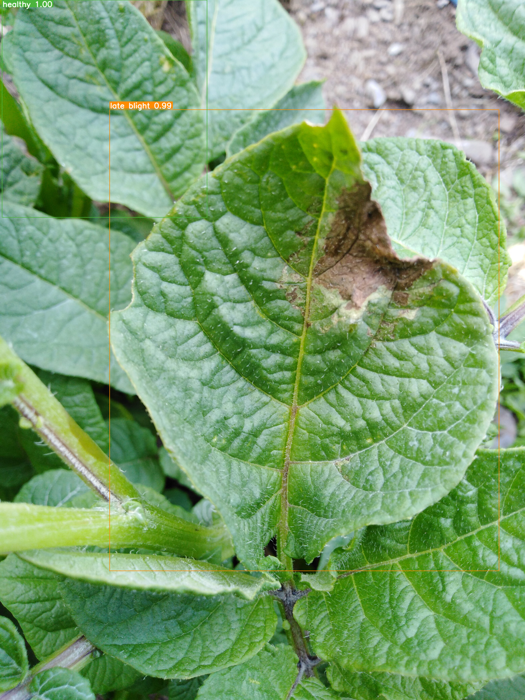

In [ ]:
from PIL import Image
import io
anotada = Image.open(io.BytesIO(requests.get(URL + resultado["image_url"], timeout=60).content))
anotada.thumbnail((700, 700))
anotada

### 9. Elegir las fotos de prueba
Por defecto 20 por clase (60 fotos, unos 3–5 minutos). Para pasar las 490, pon `POR_CLASE = None`.

In [ ]:
import pandas as pd
POR_CLASE = 20
CLASES = {"TIZON TARDIO": "late blight", "TIZON TEMPRANO": "early blight", "HOJAS SANAS": "healthy"}
EXT = (".jpg", ".jpeg", ".png", ".heic", ".heif")
filas = []
for sub, clase in CLASES.items():
    archivos = sorted(a for a in os.listdir(f"{CARPETA_FOTOS}/{sub}") if a.lower().endswith(EXT))
    for a in archivos:
        filas.append({"archivo": f"{CARPETA_FOTOS}/{sub}/{a}", "real": clase})
fotos = pd.DataFrame(filas)
if POR_CLASE:
    fotos = fotos.groupby("real", group_keys=False).apply(lambda d: d.sample(min(POR_CLASE, len(d)), random_state=0))
print(fotos.real.value_counts())

real
early blight    20
healthy         20
late blight     20
Name: count, dtype: int64


/tmp/ipykernel_1878/3860251250.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fotos = fotos.groupby("real", group_keys=False).apply(lambda d: d.sample(min(POR_CLASE, len(d)), random_state=0))


### 10. Enviar todas las fotos elegidas
Una petición por foto, una tras otra.

In [ ]:
registros = []
for i, fila in enumerate(fotos.itertuples(), 1):
    try:
        res, ms = enviar_foto(fila.archivo)
        registros.append({
            "archivo": os.path.basename(fila.archivo), "real": fila.real,
            "pred": res.get("primary_diagnosis"), "confianza": res.get("primary_score"),
            "baja_confianza": res.get("low_confidence"), "n_hojas": res.get("n_leaves"),
            "ida_vuelta_ms": ms, **{f"srv_{k}": v for k, v in res.get("timing", {}).items() if k != "image_size"},
        })
    except Exception as e:
        registros.append({"archivo": os.path.basename(fila.archivo), "real": fila.real, "error": str(e)})
    if i % 10 == 0:
        print(f"{i}/{len(fotos)}")
resultados = pd.DataFrame(registros)
print("Errores de envío:", resultados["error"].notna().sum() if "error" in resultados else 0)
resultados.head()

10/60
20/60
30/60
40/60
50/60
60/60
Errores de envío: 0


,archivo,real,pred,confianza,baja_confianza,n_hojas,ida_vuelta_ms,srv_read_ms,srv_det_ms,srv_cls_ms,srv_total_ms
0,IMG_20260124_142854.jpg,early blight,early blight,0.998551,False,2,2846.380256,407.1,1332.8,248.1,1989.3
1,IMG_20260124_144641.jpg,early blight,early blight,0.999846,False,1,12301.035482,197.6,865.4,191.4,1256.3
2,IMG_20260124_122621.jpg,early blight,early blight,0.999891,False,1,4017.518264,1740.6,871.7,106.1,2719.8
3,IMG_20260124_144229.jpg,early blight,early blight,0.999683,False,1,1753.808486,165.9,833.4,187.6,1187.7
4,IMG_20260124_151140.jpg,early blight,early blight,0.991831,False,1,1773.312585,181.5,843.4,192.7,1218.5


### 11. Tiempos de respuesta
- `srv_*`: tiempo dentro de Cloud Run (lectura, detección, clasificación, total). **Este es el que va al paper.**
- `ida_vuelta_ms`: desde Colab, incluye subir la foto por internet y la latencia de red.

In [ ]:
columnas = ["srv_read_ms", "srv_det_ms", "srv_cls_ms", "srv_total_ms", "ida_vuelta_ms"]
tiempos = resultados[columnas].describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "min", "max"]].round(0)
tiempos.columns = ["media", "mediana", "p95", "mín", "máx"]
tiempos

,media,mediana,p95,mín,máx
srv_read_ms,428.0,256.0,1742.0,12.0,1874.0
srv_det_ms,884.0,874.0,977.0,766.0,1333.0
srv_cls_ms,216.0,195.0,312.0,90.0,410.0
srv_total_ms,1529.0,1369.0,2842.0,963.0,3000.0
ida_vuelta_ms,2548.0,2341.0,4133.0,1569.0,12301.0


### 12. Exactitud en la muestra

In [ ]:
ok = resultados.dropna(subset=["pred"])
print(f"Aciertos: {(ok.real == ok.pred).sum()} de {len(ok)} ({(ok.real == ok.pred).mean()*100:.1f} %)")
pd.crosstab(ok.real, ok.pred, rownames=["Real"], colnames=["Predicho"])

Aciertos: 56 de 60 (93.3 %)


Predicho,early blight,healthy,late blight
Real,,,
early blight,20,0,0
healthy,3,17,0
late blight,1,0,19


### 13. ¿El servicio desplegado da lo mismo que el notebook 03?
Compara foto por foto con `predicciones_pipeline_principal.csv`. Lo esperado es una coincidencia de 100 % o muy cercana.

In [ ]:
ref = pd.read_csv(f"{CARPETA_03}/predicciones_pipeline_principal.csv")
ref["archivo"] = ref["archivo"].map(os.path.basename)
ref["pred_03"] = ref["pred"].str.lower()
comp = ok.merge(ref[["archivo", "pred_03", "confianza"]].rename(columns={"confianza": "conf_03"}), on="archivo", how="inner")
print(f"Fotos comparadas: {len(comp)}")
print(f"Mismo diagnóstico: {(comp.pred == comp.pred_03).sum()} de {len(comp)}")
print(f"Diferencia media de confianza: {(comp.confianza - comp.conf_03).abs().mean():.4f}")
comp[comp.pred != comp.pred_03]

Fotos comparadas: 60
Mismo diagnóstico: 60 de 60
Diferencia media de confianza: 0.0020


,archivo,real,pred,confianza,baja_confianza,n_hojas,ida_vuelta_ms,srv_read_ms,srv_det_ms,srv_cls_ms,srv_total_ms,pred_03,conf_03


### 14. Guardar resultados en Drive

In [ ]:
resultados.to_csv(f"{CARPETA_SALIDA}/pruebas_cloud_run.csv", index=False)
resumen = {
    "fotos": int(len(ok)),
    "aciertos": int((ok.real == ok.pred).sum()),
    "tiempos_ms": tiempos.to_dict(orient="index"),
    "coincidencia_con_notebook_03": f"{int((comp.pred == comp.pred_03).sum())}/{len(comp)}",
}
with open(f"{CARPETA_SALIDA}/resumen_cloud_run.json", "w") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "fotos": 60,
  "aciertos": 56,
  "tiempos_ms": {
    "srv_read_ms": {
      "media": 428.0,
      "mediana": 256.0,
      "p95": 1742.0,
      "mín": 12.0,
      "máx": 1874.0
    },
    "srv_det_ms": {
      "media": 884.0,
      "mediana": 874.0,
      "p95": 977.0,
      "mín": 766.0,
      "máx": 1333.0
    },
    "srv_cls_ms": {
      "media": 216.0,
      "mediana": 195.0,
      "p95": 312.0,
      "mín": 90.0,
      "máx": 410.0
    },
    "srv_total_ms": {
      "media": 1529.0,
      "mediana": 1369.0,
      "p95": 2842.0,
      "mín": 963.0,
      "máx": 3000.0
    },
    "ida_vuelta_ms": {
      "media": 2548.0,
      "mediana": 2341.0,
      "p95": 4133.0,
      "mín": 1569.0,
      "máx": 12301.0
    }
  },
  "coincidencia_con_notebook_03": "60/60"
}


### 15. Memoria
No se mide desde aquí. Después de correr el paso 10, ve a Cloud Run → tu servicio → **Métricas** → *Utilización de memoria* y anota el máximo.

In [19]:
CARPETA_PILOTO = f"{RAIZ}/Imagenes Piloto"
ETIQUETAS_PILOTO = {
    "IMG_AEB010.jpg": "early blight",
    "IMG_AEB016C.jpg": "early blight",
    "IMG_AEB027.jpg": "early blight",
    "IMG_AEB028.jpg": "early blight",
    "IMG_LB028.jpg": "late blight",
    "IMG_LB048.jpg": "late blight",
    "IMG_LB063.jpg": "late blight",
    "IMG_LB066.jpg": "late blight",
    "IMG_PHL015.jpg": "healthy",
    "IMG_PHL018.jpg": "healthy",
}
print(sorted(os.listdir(CARPETA_PILOTO)))

['IMG_AEB010.jpg', 'IMG_AEB016C.jpg', 'IMG_AEB027.jpg', 'IMG_AEB028.jpg', 'IMG_LB028.jpg', 'IMG_LB048.jpg', 'IMG_LB063.jpg', 'IMG_LB066.jpg', 'IMG_PHL015.jpg', 'IMG_PHL018.jpg']


In [20]:
faltan = [a for a in ETIQUETAS_PILOTO if not os.path.exists(f"{CARPETA_PILOTO}/{a}")]
print("Imágenes con etiqueta:", len(ETIQUETAS_PILOTO))
print("No encontradas:", faltan)

Imágenes con etiqueta: 10
No encontradas: []


In [21]:
import time
import requests
import pandas as pd

filas_piloto = []
for archivo, real in ETIQUETAS_PILOTO.items():
    res, ms = enviar_foto(f"{CARPETA_PILOTO}/{archivo}")
    filas_piloto.append({"archivo": archivo, "real": real, "pred": res["primary_diagnosis"],
                         "confianza": round(res["primary_score"], 3), "baja_confianza": res["low_confidence"],
                         "n_hojas": res["n_leaves"], "acierto": res["primary_diagnosis"] == real})
piloto = pd.DataFrame(filas_piloto)
piloto

,archivo,real,pred,confianza,baja_confianza,n_hojas,acierto
0,IMG_AEB010.jpg,early blight,early blight,1.000,False,1,True
1,IMG_AEB016C.jpg,early blight,early blight,1.000,False,2,True
2,IMG_AEB027.jpg,early blight,early blight,1.000,False,2,True
3,IMG_AEB028.jpg,early blight,early blight,1.000,False,1,True
4,IMG_LB028.jpg,late blight,late blight,0.988,False,4,True
5,IMG_LB048.jpg,late blight,late blight,0.820,True,2,True
6,IMG_LB063.jpg,late blight,late blight,0.959,False,2,True
7,IMG_LB066.jpg,late blight,late blight,1.000,False,2,True
8,IMG_PHL015.jpg,healthy,early blight,0.734,True,2,False
9,IMG_PHL018.jpg,healthy,healthy,0.948,False,2,True


In [22]:
aciertos = int(piloto.acierto.sum())
print(f"Sistema: {aciertos} de {len(piloto)} ({aciertos / len(piloto) * 100:.0f} %)")
print(f"Agricultores: 41,8 %")
print(f"Diferencia: {aciertos / len(piloto) * 100 - 41.8:+.1f} puntos")
piloto.to_csv(f"{CARPETA_SALIDA}/piloto_10_imagenes.csv", index=False)

Sistema: 9 de 10 (90 %)
Agricultores: 41,8 %
Diferencia: +48.2 puntos


In [23]:
import matplotlib.pyplot as plt
import io
from PIL import Image

plt.figure(figsize=(20, 10))

# Recorremos las 10 imágenes piloto para obtener y mostrar su versión anotada por el servicio
for i, (archivo, real) in enumerate(ETIQUETAS_PILOTO.items()):
    # 1. Enviar la foto para obtener la respuesta con la URL del resultado anotado
    res, ms = enviar_foto(f"{CARPETA_PILOTO}/{archivo}")

    # 2. Descargar la imagen anotada usando la URL devuelta en el resultado
    img_res = requests.get(URL + res["image_url"], timeout=60)
    img = Image.open(io.BytesIO(img_res.content))

    # 3. Mostrar la imagen en una cuadrícula de 2 filas y 5 columnas
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.axis("off")
    color = "green" if res["primary_diagnosis"] == real else "red"
    plt.title(f"{archivo}\nReal: {real}\nPred: {res['primary_diagnosis']}", color=color, fontsize=10)

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.